In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('/Users/ale/Desktop/CRIF SETTIMANA 3/Student_Depression_Dataset.csv')

df.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 722.9 KB


In [5]:
df.isnull().sum()

Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

# Chapter 1: The Face Behind the Numbers

![](https://i.imgur.com/EW7gaGP.jpeg)

Every story begins with people.

One quiet evening, Juno came across a dataset containing thousands of student records. At first glance, they looked like nothing more than rows of numbers and categories. But behind every row was a student with a different background, lifestyle, and experience.

Juno wondered: Who are the students behind these numbers, and what can their data reveal?

Before searching for hidden patterns, he decided to understand the people represented in the dataset. He began by exploring their ages, gender distribution, and reported depression status.

After all, every meaningful discovery starts with understanding the data.

In [7]:
# Dataset overview
total_students = len(df)

print(f"Total students: {total_students:,}")
print(f"Average age: {df['Age'].mean():.1f}")
print(f"Age range: {df['Age'].min()}–{df['Age'].max()}")
print(f"Number of semesters: {df['Current_semester'].nunique()}")

Total students: 4,464
Average age: 22.6
Age range: 17–28
Number of semesters: 14


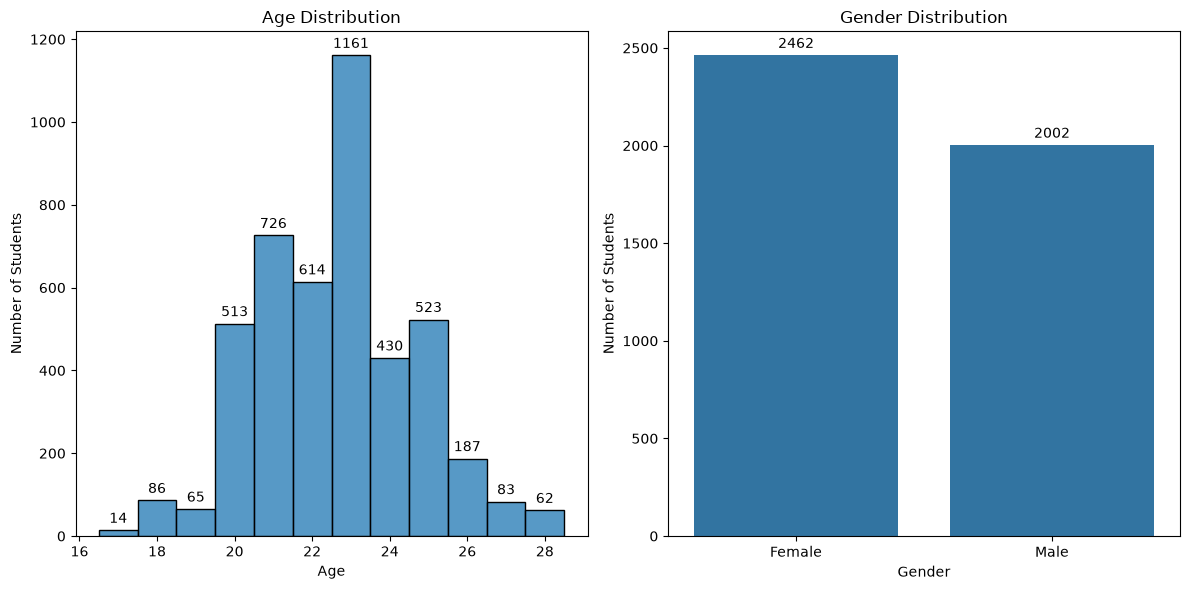

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Age Distribution
sns.histplot(
    data=df,
    x="Age",
    bins=12,
    discrete=True,
    ax=axes[0]
)
axes[0].set_title("Age Distribution")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Number of Students")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f", padding=3)

# Gender Distribution
sns.countplot(
    data=df,
    x="Gender",
    ax=axes[1]
)
axes[1].set_title("Gender Distribution")
axes[1].set_xlabel("Gender")
axes[1].set_ylabel("Number of Students")

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

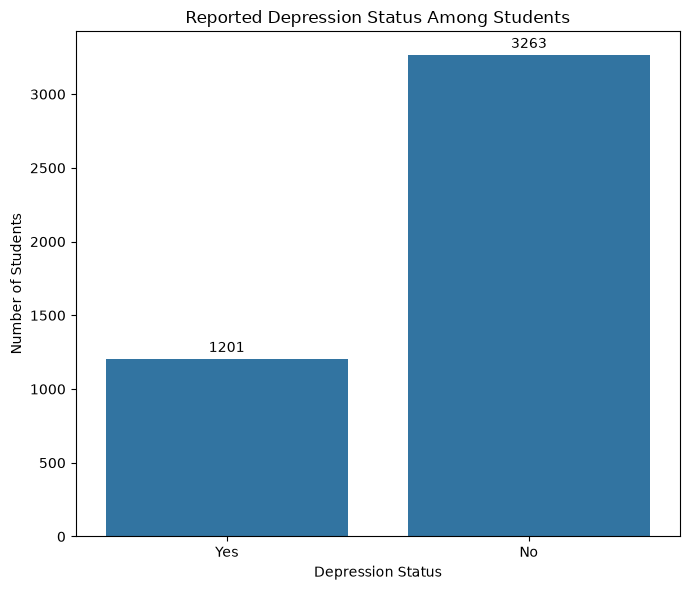

In [9]:
depression_counts = df["Depression"].value_counts()

depression_pct = (
    df["Depression"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

depression_summary = pd.DataFrame({
    "Count": depression_counts,
    "Percentage": depression_pct
})

plt.figure(figsize=(7, 6))

ax = sns.countplot(
    data=df,
    x="Depression"
)

# Add count labels above each bar
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)

ax.set_title("Reported Depression Status Among Students")
ax.set_xlabel("Depression Status")
ax.set_ylabel("Number of Students")

plt.tight_layout()
plt.show()

# Chapter 2: Searching for Hidden Patterns

![](https://i.imgur.com/Rda6hsp.jpeg)

Juno had seen the bigger picture. Thousands of students, different backgrounds, and one finding that caught his attention: 26.9% of the students were labeled as experiencing depression.

But the numbers alone couldn’t tell him much.

He began to wonder whether students’ lives shared any patterns. Could family background, relationship status, or living conditions be associated with differences in reported depression status?

To find out, Juno decided to look beyond the overall numbers and compare groups of students.

**Perhaps the clues weren’t hidden in individual records, but in the patterns connecting them.**

In [10]:
def plot_depression_comparison(column, title, order=None):
    colors = {"No": "tab:blue", "Yes": "tab:orange"}

    # Define one consistent category order for both charts
    if order is None:
        order = df[column].value_counts().index.tolist()

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Count
    sns.countplot(
        data=df,
        x=column,
        hue="Depression",
        order=order,
        hue_order=["No", "Yes"],
        palette=colors,
        ax=axes[0]
    )

    axes[0].set_title(f"Number of students by {title} and Depression Status")
    axes[0].set_xlabel(title)
    axes[0].set_ylabel("Number of Students")
    axes[0].tick_params(axis="x", rotation=15)

    for container in axes[0].containers:
        axes[0].bar_label(
            container, fmt="%.0f", padding=3, fontsize=8
        )

    # Percentage
    pct = pd.crosstab(
        df[column], df["Depression"], normalize="index"
    ).mul(100).reindex(index=order, columns=["No", "Yes"], fill_value=0)

    pct.plot(
        kind="bar",
        color=[colors["No"], colors["Yes"]],
        ax=axes[1]
    )

    axes[1].set_title(f"Depression rate within each {title} (%)")
    axes[1].set_xlabel(title)
    axes[1].set_ylabel("Percentage of Students")
    axes[1].tick_params(axis="x", rotation=15)
    axes[1].legend(title="Depression Status")

    for container in axes[1].containers:
        axes[1].bar_label(
            container, fmt="%.1f%%", padding=3, fontsize=8
        )

    plt.tight_layout()
    plt.show()

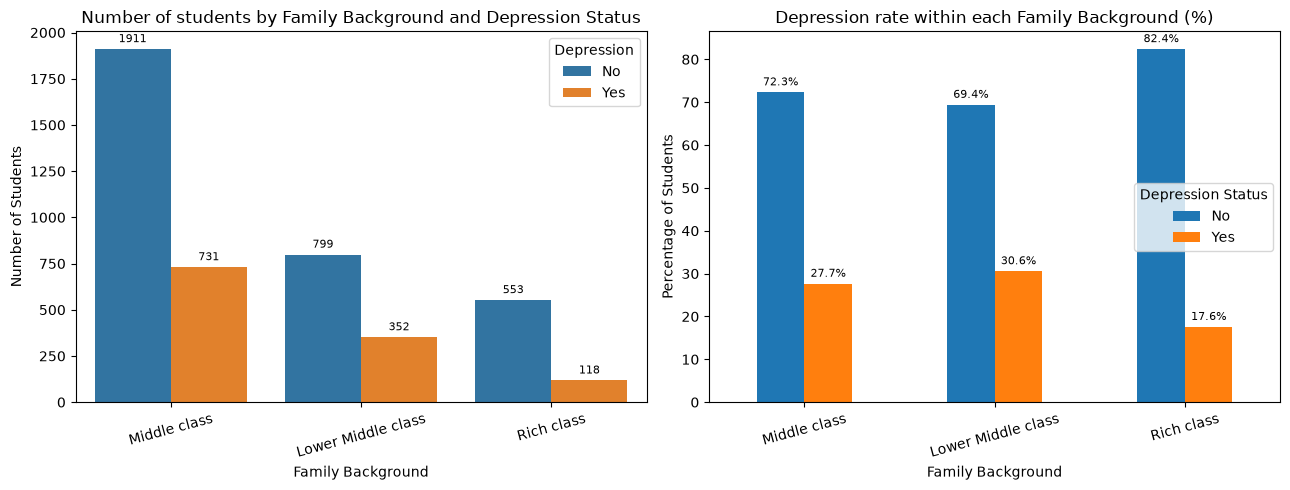

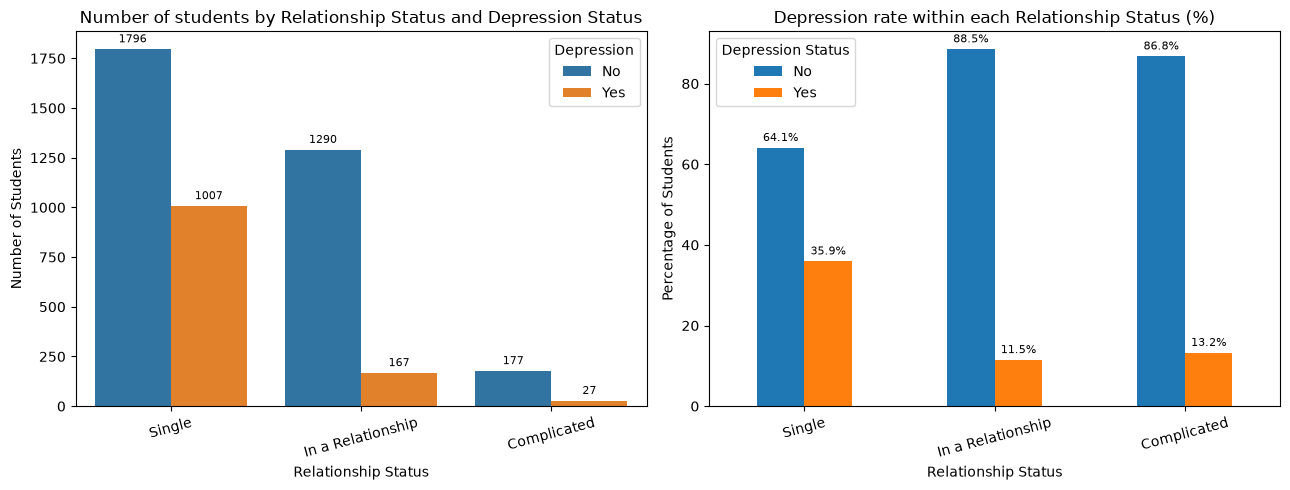

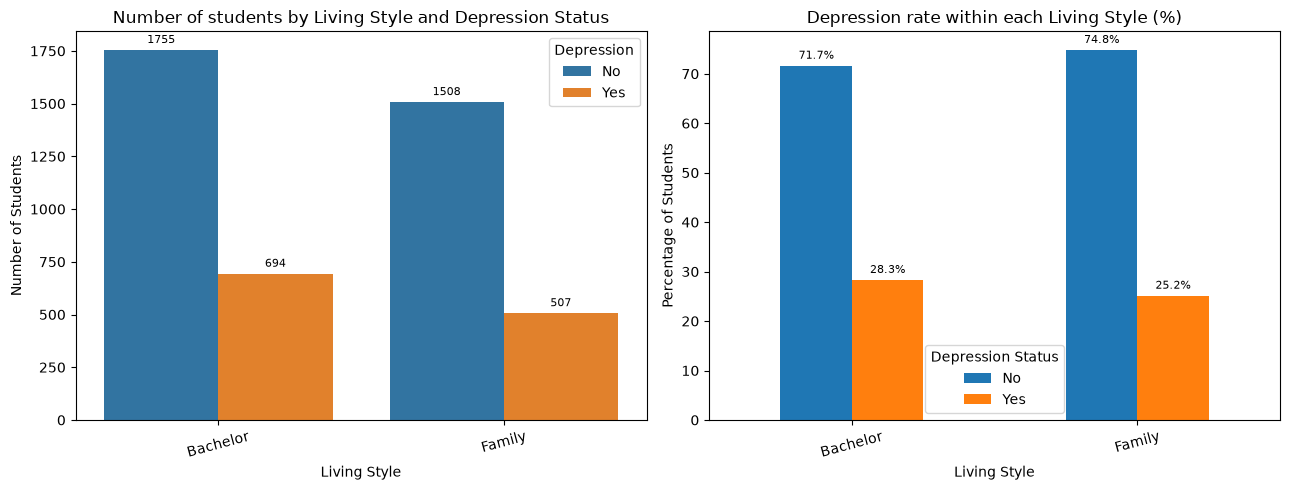

In [11]:
#1 colonna da usare
#2 titolo
plot_depression_comparison("Family_background", "Family Background")
plot_depression_comparison("Relationship_status", "Relationship Status")
plot_depression_comparison("Living_style", "Living Style")

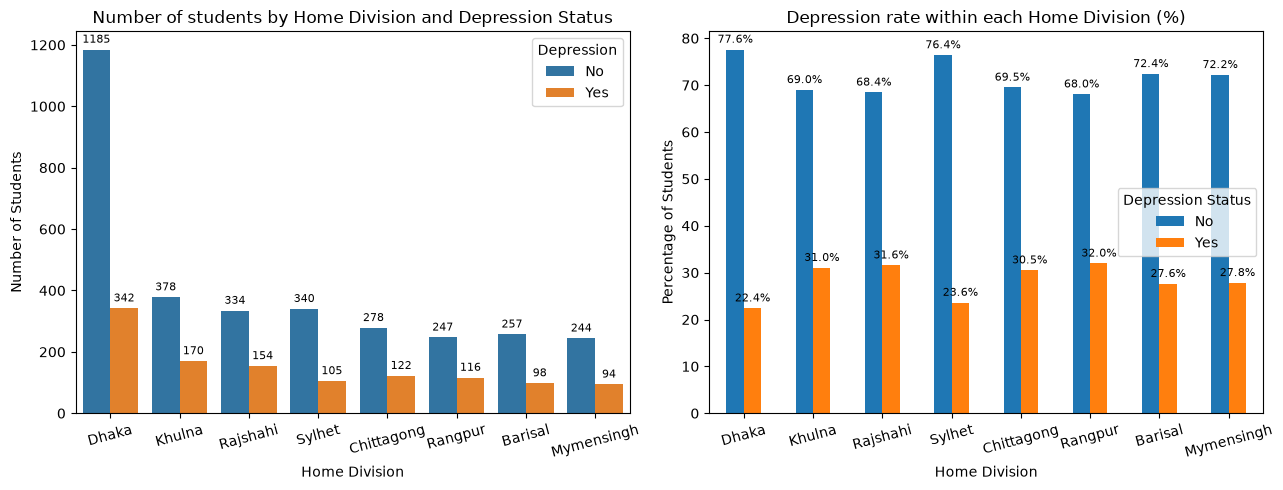

In [12]:
plot_depression_comparison("Home_division", "Home Division")


I grafici a destra mostrano la percentuale di depressi e non depressi (come si distribuisce la depressione dentro ogni classe).



As Juno compared the students, several patterns began to emerge. Single students had higher proportions of reported depression, while students from lower-middle-class backgrounds showed a higher proportion than those from rich-class backgrounds. Students categorized as living as a bachelor also showed a slightly higher proportion than those living with family.

Among these comparisons, relationship status showed the most noticeable difference. But Juno knew that a pattern was not the same as an explanation. These findings could reveal associations, not prove what causes depression.

His investigation had uncovered a few promising clues. Now, he wanted to look beyond individual characteristics and explore what other factors might help explain the differences.

The patterns were beginning to take shape, but Juno’s investigation was far from over.

# Chapter 3: Beyond the Classroom

![](https://i.imgur.com/NSp9gVr.jpeg)

Juno had explored the students’ backgrounds and discovered several intriguing patterns. But he wondered whether their experiences inside the classroom might reveal something more.

Academic life comes with its own challenges. Students move through different semesters, work toward academic goals, and receive grades that reflect their performance.

Could academic standing be associated with differences in reported depression status?

Juno decided to investigate two variables: current semester and CGPA. Perhaps examining their academic journey would reveal another piece of the puzzle.

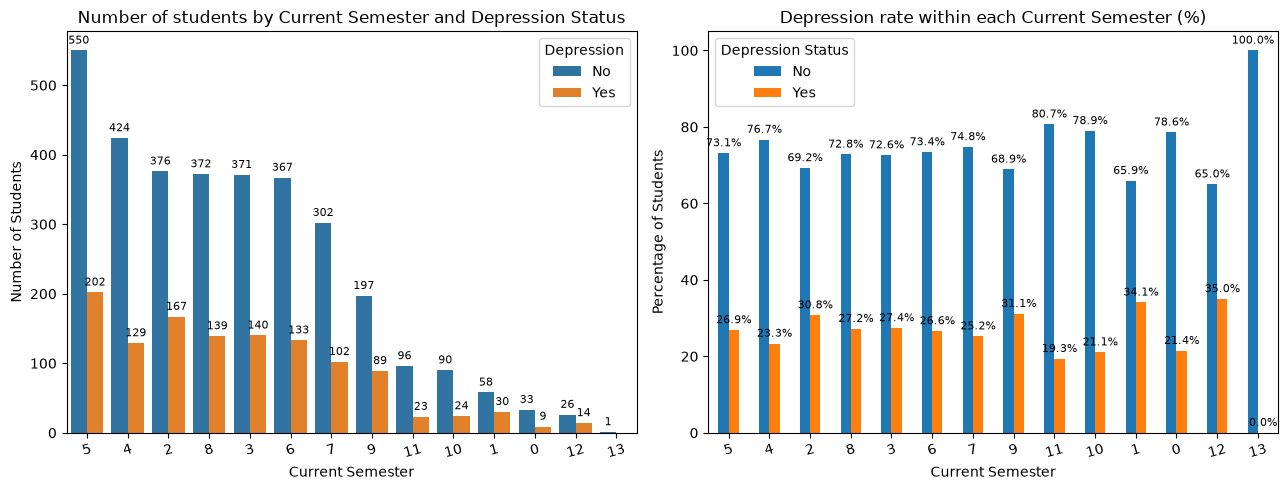

In [13]:
plot_depression_comparison("Current_semester", "Current Semester")

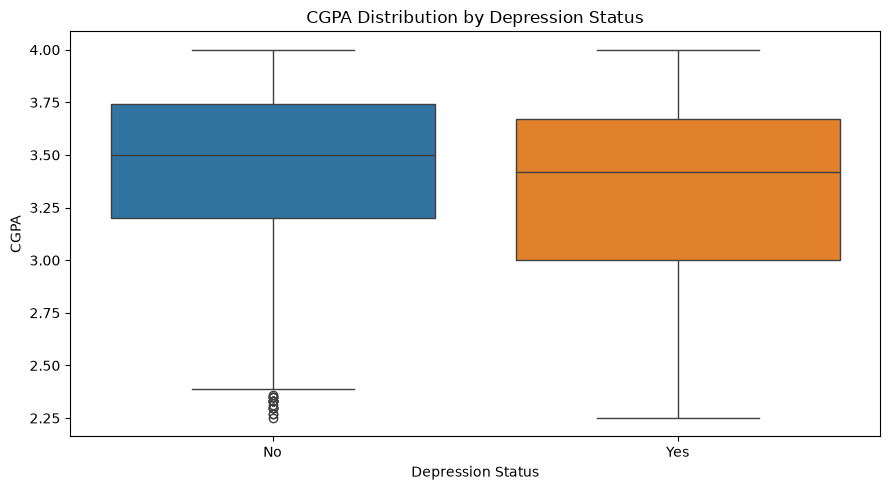

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Depression",
    y="CGPA",
    hue="Depression",
    order=["No", "Yes"],
    hue_order=["No", "Yes"],
    palette={"No": "tab:blue", "Yes": "tab:orange"},
    legend=False,
    ax=ax
)

ax.set_title("CGPA Distribution by Depression Status")
ax.set_xlabel("Depression Status")
ax.set_ylabel("CGPA")

plt.tight_layout()
plt.show()

Juno found that students labeled as experiencing depression had a slightly lower median CGPA (3.42) than those labeled as not experiencing depression (3.50). The difference was modest, suggesting that academic performance alone might not tell the whole story.

He also noticed that the proportion of students labeled as experiencing depression varied across semesters, ranging from 19.33% to 35.00%. However, some semesters had far fewer students than others, making direct comparisons less reliable.

These patterns offered new clues, but they did not establish that academic performance or semester progression caused depression. Juno realized that understanding students’ experiences required looking beyond academic indicators.

His investigation continued. This time, he would explore the role of health, social connections, and financial circumstances.

# Capitolo 4: Salute, relazioni sociali e costi

In questo capitolo si analizzano tre aspetti della vita degli studenti non ancora considerati: la condizione di salute, la cerchia di amici (da sola e insieme allo stato di relazione) e i costi legati allo studio. Per ciascuno si confronta il tasso di depressione tra i gruppi; il tasso complessivo del dataset è 26,9%.

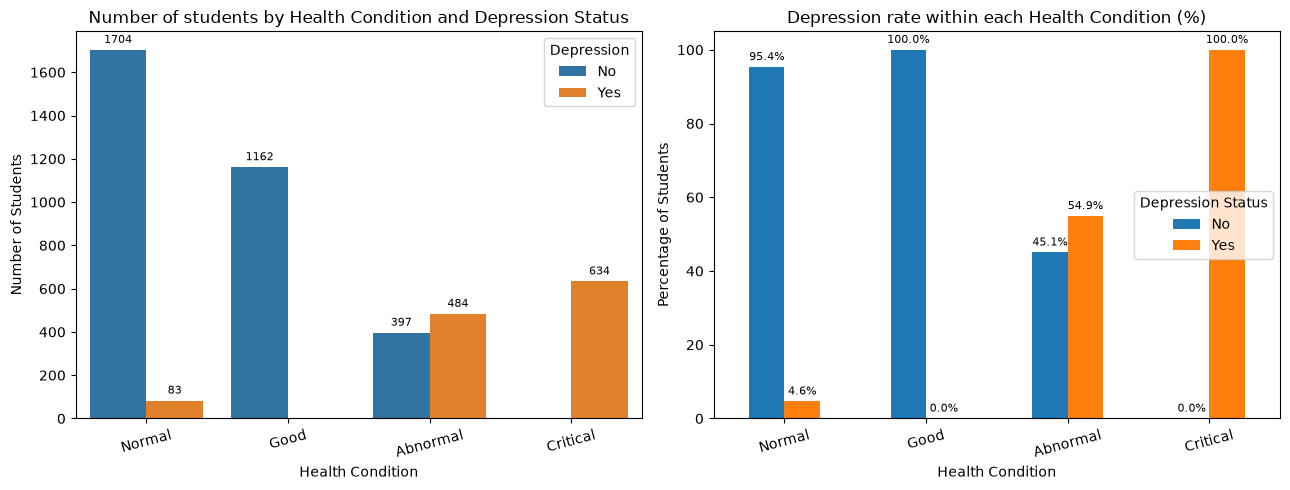

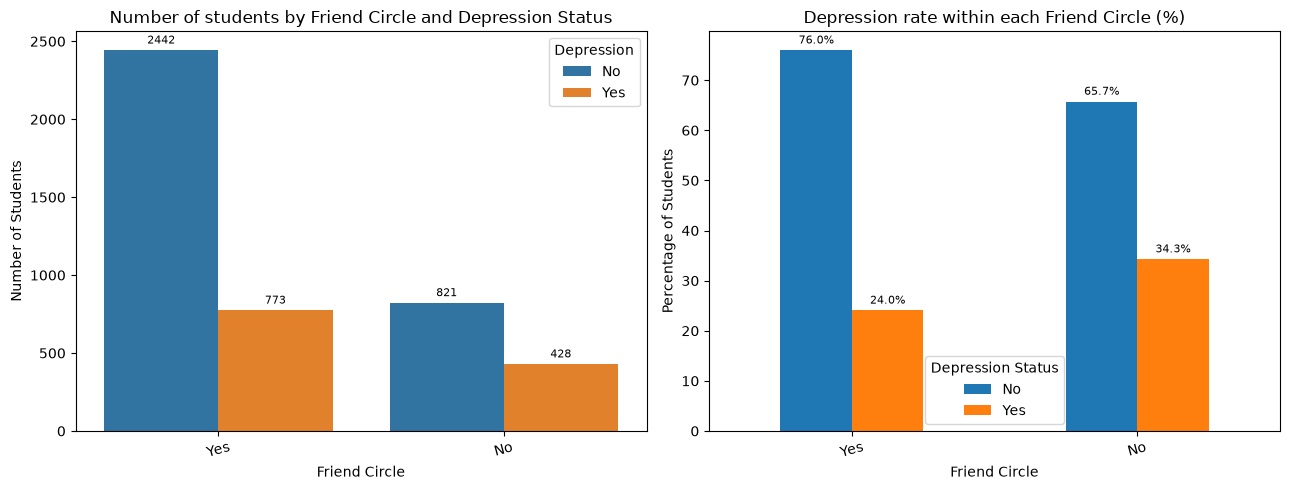

In [15]:
plot_depression_comparison("Health_condition", "Health Condition")
plot_depression_comparison("friend_circle", "Friend Circle")

In ogni coppia di grafici, a sinistra c'è il numero di studenti per categoria, diviso tra non depressi e depressi; a destra la percentuale di depressi e non depressi dentro ogni categoria, che permette di confrontare gruppi di dimensioni diverse.

- **Condizione di salute.** Il tasso di depressione è 100% tra i Critical, 54,9% tra gli Abnormal, 4,6% tra i Normal e 0% tra i Good. La differenza è così netta che viene approfondita nella tabella seguente.
- **Cerchia di amici.** Chi non ha una cerchia di amici ha un tasso di depressione del 34,3% contro il 24,0% di chi ce l'ha; il gruppo senza amici è però meno numeroso (1.249 studenti contro 3.215).

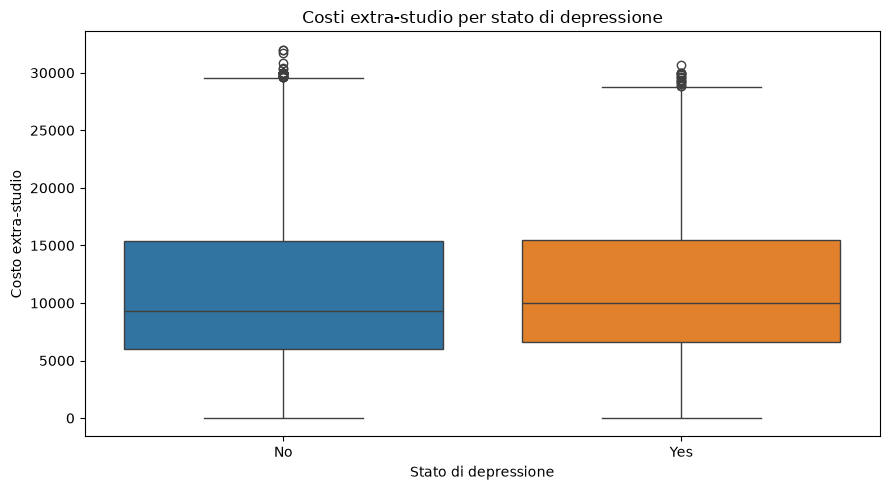

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Depression",
    y="Cost_without_study",
    hue="Depression",
    order=["No", "Yes"],
    hue_order=["No", "Yes"],
    palette={"No": "tab:blue", "Yes": "tab:orange"},
    legend=False,
    ax=ax
)

ax.set_title("Costi extra-studio per stato di depressione")
ax.set_xlabel("Stato di depressione")
ax.set_ylabel("Costo extra-studio")

plt.tight_layout()
plt.show()

Le due distribuzioni sono quasi sovrapposte: mediana 9.300 per i non depressi e 10.000 per i depressi, media 11.170 e 11.442, quartili molto vicini (25° percentile 6.000 e 6.598; 75° percentile 15.422 e 15.471). A prima vista nulla di interessante. Più avanti i costi vengono divisi in quintili.

In [17]:
# Condizione di salute vs depressione: quanto è netta la separazione?
health_table = pd.crosstab(
    df["Health_condition"], df["Depression"], margins=True
)

health_table["Tasso_depressione (%)"] = (
    health_table["Yes"] / health_table["All"] * 100
).round(2)

print(health_table)

Depression          No   Yes   All  Tasso_depressione (%)
Health_condition                                         
Abnormal           397   484   881                  54.94
Critical             0   634   634                 100.00
Good              1162     0  1162                   0.00
Normal            1704    83  1787                   4.64
All               3263  1201  4464                  26.90


La tabella conta, per ogni categoria di salute, quanti studenti sono depressi (`Yes`) e quanti no (`No`), e calcola il tasso. Tutti i 634 studenti Critical risultano depressi e nessuno dei 1.162 Good lo è; tra i Normal il tasso è 4,64%, tra gli Abnormal 54,94%.

Strana la separazione cosi netta. Può essere  che `Health_condition` non sia indipendente dall'etichetta: potrebbe essere stata costruita a partire dalla stessa valutazione, oppure contenere una componente di salute mentale. 

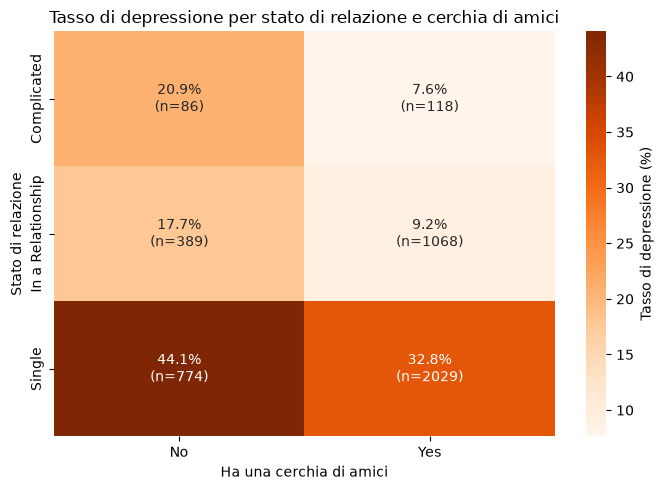

In [18]:
# Stato di relazione e cerchia di amici insieme
rate = pd.crosstab(
    df["Relationship_status"], df["friend_circle"],
    values=(df["Depression"] == "Yes"), aggfunc="mean"
).mul(100)

n = pd.crosstab(df["Relationship_status"], df["friend_circle"])

# Etichette delle celle: tasso e numero di studenti del gruppo
labels = rate.round(1).astype(str) + "%\n(n=" + n.astype(str) + ")"

fig, ax = plt.subplots(figsize=(7, 5))

sns.heatmap(
    rate,
    annot=labels,
    fmt="",
    cmap="Oranges",
    cbar_kws={"label": "Tasso di depressione (%)"},
    ax=ax
)

ax.set_title("Tasso di depressione per stato di relazione e cerchia di amici")
ax.set_xlabel("Ha una cerchia di amici")
ax.set_ylabel("Stato di relazione")

plt.tight_layout()
plt.show()

In [19]:
from scipy.stats import chi2_contingency

# per ogni stato di relazione, confrontiamo studenti con e senza amici
friend_results = []
relationship_groups = df["Relationship_status"].unique()

for group in relationship_groups:
    subset = df[df["Relationship_status"] == group]

    rate_yes = (subset.loc[subset["friend_circle"] == "Yes", "Depression"] == "Yes").mean() * 100
    rate_no = (subset.loc[subset["friend_circle"] == "No", "Depression"] == "Yes").mean() * 100

    table = pd.crosstab(subset["friend_circle"], subset["Depression"])
    chi2_f, p_f, dof_f, expected_f = chi2_contingency(table)

    friend_results.append({
        "Relationship_status": group,
        "Students": len(subset),
        "Rate (friends)": round(rate_yes, 1),
        "Rate (no friends)": round(rate_no, 1),
        "Difference": round(rate_no - rate_yes, 1),
        "P-value": p_f,
        "P-value (corrected)": min(p_f * len(relationship_groups), 1)   # Bonferroni sui 3 gruppi
    })

friend_table = pd.DataFrame(friend_results).sort_values("Students", ascending=False)

for nome_colonna in ["P-value", "P-value (corrected)"]:
    friend_table[nome_colonna] = friend_table[nome_colonna].map(
        lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}"
    )

friend_table


,Relationship_status,Students,Rate (friends),Rate (no friends),Difference,P-value,P-value (corrected)
0,Single,2803,32.8,44.1,11.2,< 0.001,< 0.001
2,In a Relationship,1457,9.2,17.7,8.6,< 0.001,< 0.001
1,Complicated,204,7.6,20.9,13.3,0.010,0.031


La heatmap incrocia stato di relazione e cerchia di amici: in ogni cella compaiono il tasso di depressione e il numero di studenti del gruppo.

- **Amici.** In tutti e tre i gruppi di relazione chi ha amici ha un tasso più basso: 32,8% contro 44,1% tra i single, 9,2% contro 17,7% tra chi è in una relazione, 7,6% contro 20,9% tra i "Complicated" (8–13 punti di differenza). Il test del chi-quadro per gruppo, con Bonferroni, è significativo in tutti e tre: p < 0,001 per Single e In a Relationship, p corretto = 0,031 per Complicated.
- **Relazione.** Essere single è associato a tassi molto più alti, sia con amici (32,8% contro 9,2%) sia senza (44,1% contro 17,7%).
- **I due fattori si sommano:** dal 9,2% di chi ha una relazione e amici al 44,1% dei single senza amici.

I gruppi "Complicated" sono piccoli (86 e 118 studenti): i loro valori sono meno affidabili.

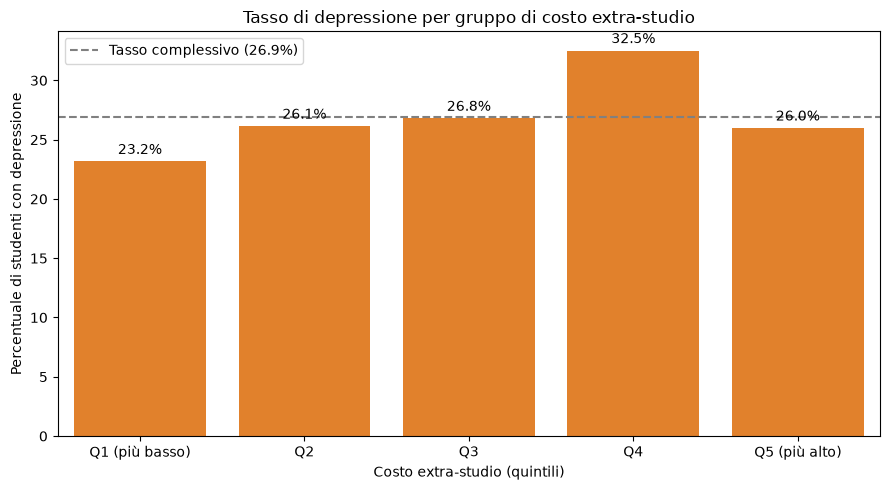

In [20]:
# Costi legati allo studio divisi in 5 gruppi di uguale ampiezza (quintili)
df["Cost_quintile"] = pd.qcut(
    df["Cost_without_study"],
    q=5,
    labels=["Q1 (più basso)", "Q2", "Q3", "Q4", "Q5 (più alto)"]
)

cost_rates = (
    df.groupby("Cost_quintile", observed=True)["Depression"]
    .agg(Students="size", Rate=lambda x: (x == "Yes").mean() * 100)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=cost_rates,
    x="Cost_quintile",
    y="Rate",
    color="tab:orange",
    ax=ax
)

# Tasso complessivo come linea di riferimento
overall_rate = (df["Depression"] == "Yes").mean() * 100
ax.axhline(overall_rate, color="gray", linestyle="--", label=f"Tasso complessivo ({overall_rate:.1f}%)")

ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_title("Tasso di depressione per gruppo di costo extra-studio")
ax.set_xlabel("Costo extra-studio (quintili)")
ax.set_ylabel("Percentuale di studenti con depressione")
ax.legend()

plt.tight_layout()
plt.show()

Il tasso di depressione sale dal 23,2% del gruppo di costo più basso al 32,5% del quarto, poi scende al 26,0% nel quinto, vicino al tasso complessivo (26,9%, linea tratteggiata). L'andamento non è crescente: il boxplot, che confronta solo il valore centrale, non poteva mostrarlo. I cinque gruppi hanno circa 890 studenti ciascuno, quindi differenze di pochi punti possono essere dovute alla variabilità del campione; la più marcata è quella del quarto gruppo rispetto al primo.

In [21]:
#ci chiediamo se le differenze dei quantili plottate sopra sono casuali
#testiamo l'ipotesi che il costo extra-studio non c'entri con la depressione

#tabella con quintili di costo nelle righe e depressione colonne
cost_table = pd.crosstab(df["Cost_quintile"], df['Depression'])
print(cost_table)



Depression       No  Yes
Cost_quintile           
Q1 (più basso)  700  211
Q2              650  230
Q3              650  238
Q4              602  290
Q5 (più alto)   661  232


In [22]:
from scipy.stats import chi2_contingency
chi2, p_value, dof, expected = chi2_contingency(cost_table)
print(f"Chi-quadro = {chi2:.2f}, gradi di libertà = {dof}, p-value = {p_value:.5f}")

n = cost_table.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n * min(cost_table.shape[0] - 1, cost_table.shape[1] - 1)))
print(f"V di Cramér = {cramers_v:.3f}")

Chi-quadro = 21.41, gradi di libertà = 4, p-value = 0.00026
V di Cramér = 0.069


Il test del chi-quadro sui cinque gruppi indica che il tasso di depressione varia con il costo (p = 0,00026), quindi la differenza osservata difficilmente è dovuta al caso. L'effetto però è trascurabile

In [23]:
quintile_results = []

for q in df["Cost_quintile"].cat.categories:
    in_group = df["Cost_quintile"] == q

    # tasso dentro il quintile e tasso nel resto degli studenti
    rate_in = (df.loc[in_group, "Depression"] == "Yes").mean() * 100
    rate_out = (df.loc[~in_group, "Depression"] == "Yes").mean() * 100

    table = pd.crosstab(in_group, df["Depression"])
    chi2, p_value, dof, expected = chi2_contingency(table)

    quintile_results.append({
        "Quintile": q,
        "Rate (quintile)": round(rate_in, 1),
        "Rate (others)": round(rate_out, 1),
        "P-value": p_value,
        "P-value (corrected)": min(p_value * 5, 1)
    })

quintile_table = pd.DataFrame(quintile_results)

for nome_colonna in ["P-value", "P-value (corrected)"]:
    quintile_table[nome_colonna] = quintile_table[nome_colonna].map(
        lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}"
    )

quintile_table


,Quintile,Rate (quintile),Rate (others),P-value,P-value (corrected)
0,Q1 (più basso),23.2,27.9,0.005,0.025
1,Q2,26.1,27.1,0.596,1.000
2,Q3,26.8,26.9,0.972,1.000
3,Q4,32.5,25.5,< 0.001,< 0.001
4,Q5 (più alto),26.0,27.1,0.513,1.000


Confrontiamo ogni quintile con tutti gli altri, correggendo i p-value con Bonferroni per i 5 confronti. La differenza viene dai due estremi: il quarto gruppo ha un tasso più alto (32,5% contro 25,5% negli altri; p < 0,001) e il primo più basso (23,2% contro 27,9%; p corretto = 0,025). Secondo, terzo e quinto gruppo non si distinguono dal resto (p corretto = 1).

In [24]:
# costo mediano per classe sociale
print(df.groupby("Family_background")["Cost_without_study"].median())

# tasso di depressione per quintile di costo, dentro ogni classe sociale
class_rates = pd.crosstab(
    df["Cost_quintile"], df["Family_background"],
    values=(df["Depression"] == "Yes"), aggfunc="mean"
).mul(100)
class_counts = pd.crosstab(df["Cost_quintile"], df["Family_background"])

# le celle con meno di 30 studenti non vengono mostrate (troppo instabili)
class_rates = class_rates.where(class_counts >= 30).round(1)

print()
print("Tasso di depressione (%)")
print(class_rates)
print()
print("Numero di studenti")
print(class_counts)

Family_background
Lower Middle class     6100.0
Middle class          11304.5
Rich class            22702.0
Name: Cost_without_study, dtype: float64

Tasso di depressione (%)
Family_background  Lower Middle class  Middle class  Rich class
Cost_quintile                                                  
Q1 (più basso)                   26.4          20.9         7.8
Q2                               34.8          24.1         9.2
Q3                               34.2          23.9        10.0
Q4                                NaN          33.5         NaN
Q5 (più alto)                     NaN          30.4        22.0

Numero di studenti
Family_background  Lower Middle class  Middle class  Rich class
Cost_quintile                                                  
Q1 (più basso)                    496           364          51
Q2                                319           452         109
Q3                                304           544          40
Q4                                 26

In [25]:
#scegliamo la classe media perchè è quella con una composizione più omogenea
middle = df[df["Family_background"] == "Middle class"]
middle_table = pd.crosstab(middle["Cost_quintile"], middle["Depression"])
chi2_m, p_m, dof_m, expected_m = chi2_contingency(middle_table)

n_m = middle_table.to_numpy().sum()
v_m = np.sqrt(chi2_m / (n_m * min(middle_table.shape[0] - 1, middle_table.shape[1] - 1)))
print(f"Classe media: chi-quadro = {chi2_m:.2f}, gradi di libertà = {dof_m}, p-value = {p_m:.5f}, V di Cramér = {v_m:.3f}")

# classe ricca: quinto quintile contro i primi quattro
rich = df[df["Family_background"] == "Rich class"]
is_q5 = rich["Cost_quintile"] == "Q5 (più alto)"
print(f"Classe ricca: quinto quintile {(rich.loc[is_q5, 'Depression'] == 'Yes').mean() * 100:.1f}% (n={is_q5.sum()}), primi quattro {(rich.loc[~is_q5, 'Depression'] == 'Yes').mean() * 100:.1f}% (n={(~is_q5).sum()})")

Classe media: chi-quadro = 31.19, gradi di libertà = 4, p-value = 0.00000, V di Cramér = 0.109
Classe ricca: quinto quintile 22.0% (n=449), primi quattro 8.6% (n=222)


I costi dipendono molto dalla classe sociale: la mediana è 6.100 per la classe Lower Middle, circa 11.300 per la Middle e circa 22.700 per la Rich. Per questo i quintili hanno composizioni molto diverse: il quinto gruppo è fatto per circa metà (449 studenti su 893) da studenti della classe Rich, che hanno il tasso di depressione più basso tra le classi sociali (17,59%), mentre il quarto è quasi solo di classe Middle (844 su 892).

Guardando dentro ogni classe il quadro cambia. Nella classe media, l'unica con tutti i quintili ben popolati, il tasso sale dal 20,9% del primo quintile al 33,5% del quarto e al 30,4% del quinto (chi-quadro: p < 0,001, V di Cramér = 0,109, effetto debole). Nella classe Rich il quinto quintile ha il 22,0% (449 studenti) contro l'8,6% dei primi quattro insieme (222 studenti). Nella classe Lower Middle i quintili 2 e 3 hanno tassi più alti del primo (34,8% e 34,2% contro 26,4%), ma i quintili alti sono quasi vuoti.

Dentro ogni classe, quindi, costi più alti sono associati a tassi più alti, e il calo apparente nell'ultimo quintile del quadro generale è in buona parte un effetto di composizione. Le celle con meno di 30 studenti (Lower Middle nel quarto e quinto quintile, Rich nel quarto) non sono mostrate.


**Salute.** La separazione quasi perfetta dall'etichetta (Critical 100%, Good 0%) indica che la variabile non è indipendente dalla depressione: si descrive ma non si usa come fattore esplicativo.

**Amici e relazione.** L'assenza di amici è associata a tassi più alti in tutti i gruppi di relazione (test significativi dopo la correzione), e l'essere single sia con sia senza amici. I due fattori si sommano: dal 9,2% di chi ha una relazione e amici al 44,1% dei single senza amici.

**Costi.** Le medie dei due gruppi sono vicine. Per quintili il tasso varia in modo non lineare (p < 0,001, effetto trascurabile, V = 0,07), con il quarto gruppo più alto (32,5%) e il primo più basso (23,2%). Dentro ogni classe sociale, però, costi più alti sono associati a tassi più alti: il calo dell'ultimo quintile dipende dalla composizione (metà del quinto gruppo è di classe Rich).



Confrontiamo adesso se le differenze osservate possano essere dovute al caso, se ne misura l'intensità e si analizzano combinazioni di più caratteristiche (profili). L'analisi procede in tre passi: variabili categoriche (chi-quadro), variabili numeriche (Mann-Whitney) e profili degli studenti.

In [26]:
categorical_columns = [
    "Gender",
    "Family_background",
    "Relationship_status",
    "Living_style",
    "Health_condition",
    "friend_circle",
    "Home_division"
]

summary_list = []

for col in categorical_columns:
    tab = pd.crosstab(df[col], df['Depression'])
    tab['Count'] = tab['No'] + tab['Yes']
    tab['Depression_Rate'] = tab['Yes'] / tab['Count'] *100
    summary = tab.reset_index()
    summary['Variable'] = col
    summary = summary.rename(columns={col:'Category'})
    summary_list.append(summary)

depression_rates = pd.concat(summary_list, ignore_index=True)

depression_rates = depression_rates[
    ["Variable", "Category","Count", "Depression_Rate"]
].sort_values("Depression_Rate", ascending=False)

depression_rates["Depression_Rate"] = (
    depression_rates["Depression_Rate"].round(2)
)

print(depression_rates.to_string(index=False))

           Variable           Category  Count  Depression_Rate
   Health_condition           Critical    634           100.00
   Health_condition           Abnormal    881            54.94
Relationship_status             Single   2803            35.93
      friend_circle                 No   1249            34.27
      Home_division            Rangpur    363            31.96
      Home_division           Rajshahi    488            31.56
      Home_division             Khulna    548            31.02
  Family_background Lower Middle class   1151            30.58
      Home_division         Chittagong    400            30.50
       Living_style           Bachelor   2449            28.34
      Home_division         Mymensingh    338            27.81
  Family_background       Middle class   2642            27.67
      Home_division            Barisal    355            27.61
             Gender               Male   2002            27.27
             Gender             Female   2462          

La tabella riporta, per ogni categoria, il numero di studenti e la percentuale etichettata come depressa, in ordine decrescente. Il tasso complessivo del dataset è 26,9%. Le categorie agli estremi (Critical 100%, Abnormal 54,94%, Normal 4,64%, Good 0%) appartengono tutte a `Health_condition`, già discussa nel capitolo 4. Escludendola, i tassi più alti si trovano tra i single (35,93%) e tra chi non ha amici (34,27%), i più bassi tra chi è in una relazione (11,46%) e tra chi è in una relazione "Complicated" (13,24%).

Per ogni variabile categorica ci si chiede: conoscere la categoria di uno studente cambia la probabilità che sia depresso? Se la variabile non c'entrasse, i tassi sarebbero simili in tutte le categorie. Il test del chi-quadro misura quanto i tassi osservati si discostano da questa situazione. La tabella seguente è ordinata per V di Cramér, cioè per forza dell'associazione.

In [27]:
from scipy.stats import chi2_contingency
import numpy as np

association_results = []

for col in categorical_columns:
    contingency_table = pd.crosstab(df[col], df["Depression"]) #di nuovo tabella yes/no per ogni categoria

    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    n = contingency_table.to_numpy().sum() #trasformiamo la tabella in griglia di numeri
    r, k = contingency_table.shape #righe e colonne. le assegnamo (ogni colonna prenderà questi valori)


    denominator = n * min(r - 1, k - 1)
    cramers_v = np.sqrt(chi2 / denominator) if denominator > 0 else np.nan
    if cramers_v <0.1:
        strength = 'Negligible'
    elif cramers_v <0.3:
        strength = 'Weak'
    elif cramers_v < 0.5:
        strength = 'Moderate'
    else:
        strength = 'Strong'

    p_corrected = min(p_value * len(categorical_columns), 1)
    
    association_results.append({
        "Variable": col,
        "Chi-square": round(chi2, 2),
        "Degrees of Freedom": dof,
        "P-value": p_value,
        "Cramer's V": round(cramers_v, 3),
        "Strength": strength,
        "P-value (corrected)": p_corrected,

    })

association_table = pd.DataFrame(association_results)

for nome_colonna in ["P-value", "P-value (corrected)"]:
    association_table[nome_colonna] = association_table[nome_colonna].map(
        lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}"
    )

association_table = association_table.sort_values("Cramer's V", ascending=False)
print(association_table.to_string(index=False))

           Variable  Chi-square  Degrees of Freedom P-value  Cramer's V   Strength P-value (corrected)
   Health_condition     2952.51                   3 < 0.001       0.813     Strong             < 0.001
Relationship_status      312.06                   2 < 0.001       0.264       Weak             < 0.001
      friend_circle       47.29                   1 < 0.001       0.103       Weak             < 0.001
  Family_background       38.33                   2 < 0.001       0.093 Negligible             < 0.001
      Home_division       35.92                   7 < 0.001       0.090 Negligible             < 0.001
       Living_style        5.51                   1   0.019       0.035 Negligible               0.132
             Gender        0.22                   1   0.641       0.007 Negligible               1.000


**Chi-quadro:** confronta i conteggi osservati con quelli attesi se la variabile non fosse legata alla depressione. Più è alto, più i dati si allontanano da questa situazione.

**P-value:** probabilità di osservare una differenza almeno così grande se in realtà non ci fosse alcun legame. Un valore basso (< 0,05) indica che la differenza difficilmente è dovuta al caso, ma non dice quanto sia grande.

**V di Cramér:** misura la forza dell'associazione, da 0 (nessuna) a 1 (massima). Serve perché con molti dati anche differenze minime hanno un p-value molto basso.

Eseguendo 7 test aumenta la probabilità di ottenere almeno un falso positivo (un legame che sembra significativo solo per caso). Per questo si applica la correzione di Bonferroni: ogni p-value viene moltiplicato per il numero di test (7). Dopo la correzione restano significative cinque variabili su sette; cambia l'esito per `Living_style` (p da 0,019 a 0,132), mentre `Gender` non era significativa nemmeno prima.

`Health_condition` ha l'associazione più forte (V = 0,81), ma, come visto nel capitolo 4, la separazione quasi perfetta dall'etichetta suggerisce che non sia indipendente da essa: si esclude dalle conclusioni. Tra le altre variabili, `Relationship_status` ha l'associazione più forte (V = 0,26), seguita da `friend_circle` (0,10), entrambe deboli. `Family_background` e `Home_division` sono trascurabili (V ≈ 0,09). `Living_style` e `Gender` non sono significative dopo la correzione.

In [28]:
# tasso di depressione per genere, dentro ogni stato di relazione
gender_rates = pd.crosstab(
    df["Relationship_status"], df["Gender"],
    values=(df["Depression"] == "Yes"), aggfunc="mean"
).mul(100).round(1)

gender_counts = pd.crosstab(df["Relationship_status"], df["Gender"])

print("Tasso di depressione (%)")
print(gender_rates)
print()
print("Numero di studenti")
print(gender_counts)

Tasso di depressione (%)
Gender               Female  Male
Relationship_status              
Complicated            16.3  10.4
In a Relationship      14.1   0.0
Single                 40.0  33.0

Numero di studenti
Gender               Female  Male
Relationship_status              
Complicated              98   106
In a Relationship      1184   273
Single                 1180  1623


Il genere da solo non è associato alla depressione (27,3% degli uomini, 26,6% delle donne). Guardando il genere dentro ogni stato di relazione, però, le donne hanno un tasso più alto in tutti e tre i gruppi. Nel totale la differenza non si vede perché uomini e donne si distribuiscono in modo diverso tra gli stati di relazione: la maggior parte degli uomini è single (il gruppo con il tasso più alto), mentre tra le donne i single sono circa la metà. Il tasso dello 0% tra gli uomini in una relazione (0 su 273) è anomalo e va considerato con cautela. I valori sono descrittivi: non sono stati sottoposti a test.

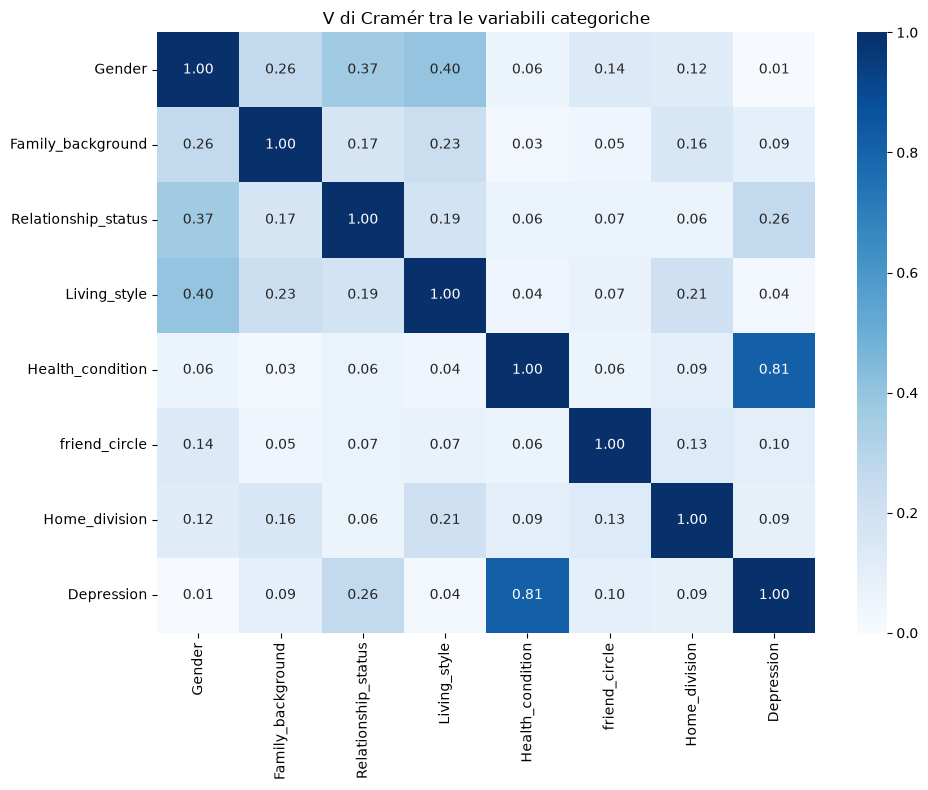

In [29]:
# V di Cramér tra ogni coppia di variabili categoriche (compresa la depressione)
cat_cols = categorical_columns + ["Depression"]

cramers_matrix = pd.DataFrame(index=cat_cols, columns=cat_cols, dtype=float)

for a in cat_cols:
    for b in cat_cols:
        table = pd.crosstab(df[a], df[b])
        chi2 = chi2_contingency(table)[0]
        n = table.to_numpy().sum()
        cramers_matrix.loc[a, b] = np.sqrt(chi2 / (n * (min(table.shape) - 1)))


fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    cramers_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    ax=ax
)

ax.set_title("V di Cramér tra le variabili categoriche")

plt.tight_layout()
plt.show()



Il V di Cramér tra le variabili categoriche mostra che la maggior parte delle coppie ha associazioni deboli (sotto 0,2). Le più forti riguardano il genere, che è legato allo stile di vita (V = 0,40) e allo stato di relazione (V = 0,37): è la ragione per cui il genere, da solo, non risulta associato alla depressione (gli uomini sono concentrati tra i single). La condizione di salute non è legata a nessuna delle altre variabili (V tra 0,03 e 0,09) ma lo è fortemente alla depressione (0,81): questo rafforza l'ipotesi che sia legata all'etichetta e non alle caratteristiche degli studenti.

Il test di Mann-Whitney confronta due gruppi (qui depressi e non depressi) su una variabile numerica, senza richiedere che i dati siano distribuiti normalmente. A differenza del chi-quadro, che lavora sulle categorie, qui si lavora direttamente sui valori: il test li mette in ordine tutti insieme e verifica se un gruppo si trova sistematicamente più in basso dell'altro.

Alla tabella si aggiungono due elementi: il p-value corretto con Bonferroni sui 4 test numerici (come fatto per i chi-quadro) e la dimensione dell'effetto A. A è la probabilità che, scegliendo a caso un non depresso e un depresso, il non depresso abbia il valore più alto: 0,50 indica nessuna differenza, e più ci si allontana da 0,50 più l'effetto è grande.

In [30]:
from scipy.stats import mannwhitneyu
import pandas as pd

numeric_columns = [
    "Age",
    "Current_semester",
    "CGPA",
    "Cost_without_study"
]

results = []

for col in numeric_columns:
    no_group = df.loc[df["Depression"] == "No", col]
    yes_group = df.loc[df["Depression"] == "Yes", col]
#ad esempio, per col 'CGPA' no_group conterrà i CGPA dei non depressi mentre yes_group que
    statistic, p_value = mannwhitneyu(
        no_group,
        yes_group,
        alternative="two-sided"
    )
#statistic è il numero di coppie in cui il non depresso ha il valore più alto
    results.append({
        "Variable": col,
        "Median (No)": no_group.median(),
        "Median (Yes)": yes_group.median(),
        "Mean (No)": no_group.mean(),
        "Mean (Yes)": yes_group.mean(),
        "U Statistic": statistic,
        "P-value": p_value
    })

numeric_association_table = pd.DataFrame(results)
#Applico Bonferrori sui test numerici (cioè sui 4 p-value)
#per essere coerente con quanto fatto sopra
numeric_association_table["P-value corrected"] =(
    numeric_association_table['P-value'] * len(numeric_columns)
).clip(upper =1)
#analizziamo la dimensione dell'effetto: dividiamo U vs il numero di coppie possibili
#cerchiamo di dimostrare le probabilità che un non depresso abbia un valore più alto di un depresso
n_no = (df['Depression'] == 'No').sum()
n_yes = (df['Depression'] == 'Yes').sum()

numeric_association_table['Effect size (A)'] = (
    numeric_association_table['U Statistic'] / (n_no * n_yes)
)

#formattiamo sia il p-value che il p-value corretto
for nome_colonna in ["P-value", "P-value corrected"]:
    numeric_association_table[nome_colonna] = (
        numeric_association_table[nome_colonna]
        .map(lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}")
    )

numeric_association_table[
    ["Median (No)", "Median (Yes)", "Mean (No)", "Mean (Yes)", "U Statistic", "Effect size (A)"]
] = numeric_association_table[
    ["Median (No)", "Median (Yes)", "Mean (No)", "Mean (Yes)", "U Statistic", "Effect size (A)"]
].round(2)

numeric_association_table

,Variable,Median (No),Median (Yes),Mean (No),Mean (Yes),U Statistic,P-value,P-value corrected,Effect size (A)
0,Age,23.0,23.00,22.66,22.51,2057404.0,0.009,0.037,0.53
1,Current_semester,5.0,5.00,5.43,5.33,2003439.5,0.246,0.983,0.51
2,CGPA,3.5,3.42,3.44,3.35,2195667.0,< 0.001,< 0.001,0.56
3,Cost_without_study,9300.0,10000.00,11169.58,11442.40,1871265.0,0.021,0.084,0.48


**Age.** La differenza è significativa dopo la correzione (p = 0,037) ma l'effetto è trascurabile (A = 0,53): le mediane coincidono (23 anni in entrambi i gruppi).

**Current_semester.** Nessuna differenza (p = 0,983; A = 0,51): il semestre non distingue i due gruppi.

**CGPA.** La differenza è chiara (p < 0,001): mediana 3,50 per i non depressi contro 3,42 per i depressi. Con A = 0,56, scegliendo a caso un non depresso e un depresso, il non depresso ha il CGPA più alto nel 56% dei casi. È l'effetto maggiore della tabella, ma resta piccolo.

**Cost_without_study.** I depressi hanno costi leggermente più alti (mediana 10.000 contro 9.300; A = 0,48, sotto 0,50 perché il segno è opposto), ma dopo la correzione la differenza non è significativa (p = 0,084) e l'effetto è trascurabile.

 CGPA_quintile  CGPA_min  CGPA_max  Students  Rate
C1 (più basso)      2.25      3.03       894 35.46
            C2      3.04      3.37       896 26.79
            C3      3.38      3.58       928 24.89
            C4      3.59      3.77       881 24.97
 C5 (più alto)      3.78      4.00       865 22.31


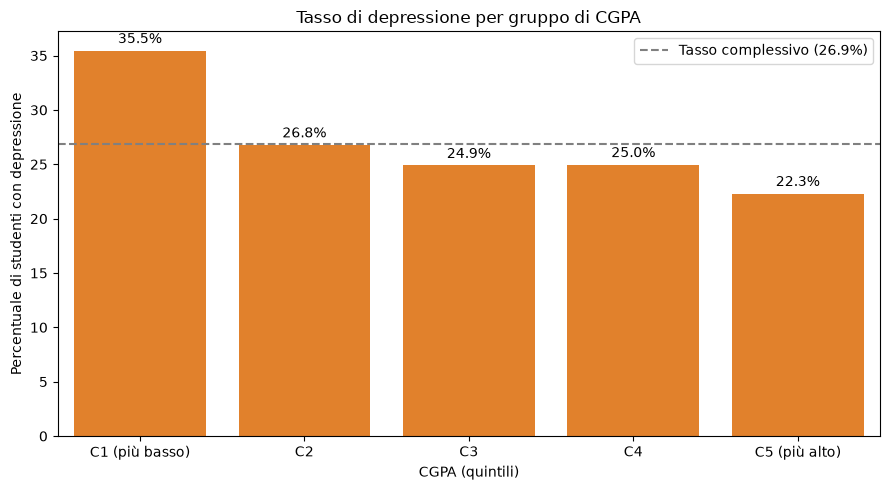

In [31]:
# CGPA diviso in 5 gruppi di uguale ampiezza (quintili)
df["CGPA_quintile"] = pd.qcut(
    df["CGPA"],
    q=5,
    labels=["C1 (più basso)", "C2", "C3", "C4", "C5 (più alto)"]
)

cgpa_rates = (
    df.groupby("CGPA_quintile", observed=True)
    .agg(
        CGPA_min=("CGPA", "min"),
        CGPA_max=("CGPA", "max"),
        Students=("Depression", "size"),
        Rate=("Depression", lambda x: (x == "Yes").mean() * 100)
    )
    .reset_index()
)

print(cgpa_rates.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=cgpa_rates,
    x="CGPA_quintile",
    y="Rate",
    color="tab:orange",
    ax=ax
)

# Tasso complessivo come linea di riferimento
overall_rate = (df["Depression"] == "Yes").mean() * 100
ax.axhline(overall_rate, color="gray", linestyle="--", label=f"Tasso complessivo ({overall_rate:.1f}%)")

ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_title("Tasso di depressione per gruppo di CGPA")
ax.set_xlabel("CGPA (quintili)")
ax.set_ylabel("Percentuale di studenti con depressione")
ax.legend()

plt.tight_layout()
plt.show()

In [32]:
# test del chi-quadro sui cinque gruppi di CGPA
cgpa_table = pd.crosstab(df["CGPA_quintile"], df["Depression"])
chi2_cg, p_cg, dof_cg, expected_cg = chi2_contingency(cgpa_table)
print(f"Chi-quadro = {chi2_cg:.2f}, gradi di libertà = {dof_cg}, p-value = {p_cg:.8f}")

n_cg = cgpa_table.to_numpy().sum()
v_cg = np.sqrt(chi2_cg / (n_cg * min(cgpa_table.shape[0] - 1, cgpa_table.shape[1] - 1)))
print(f"V di Cramér = {v_cg:.3f}")

# ogni quintile contro tutti gli altri, con Bonferroni sui 5 confronti
cgpa_results = []

for q in df["CGPA_quintile"].cat.categories:
    in_group = df["CGPA_quintile"] == q

    # tasso dentro il quintile e tasso nel resto degli studenti
    rate_in = (df.loc[in_group, "Depression"] == "Yes").mean() * 100
    rate_out = (df.loc[~in_group, "Depression"] == "Yes").mean() * 100

    table_cg = pd.crosstab(in_group, df["Depression"])
    p_q_cg = chi2_contingency(table_cg)[1]

    cgpa_results.append({
        "Quintile": q,
        "Rate (quintile)": round(rate_in, 1),
        "Rate (others)": round(rate_out, 1),
        "P-value": p_q_cg,
        "P-value (corrected)": min(p_q_cg * 5, 1)
    })

cgpa_quintile_table = pd.DataFrame(cgpa_results)

for nome_colonna in ["P-value", "P-value (corrected)"]:
    cgpa_quintile_table[nome_colonna] = cgpa_quintile_table[nome_colonna].map(
        lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}"
    )

cgpa_quintile_table

Chi-quadro = 46.13, gradi di libertà = 4, p-value = 0.00000000
V di Cramér = 0.102


,Quintile,Rate (quintile),Rate (others),P-value,P-value (corrected)
0,C1 (più basso),35.5,24.8,< 0.001,< 0.001
1,C2,26.8,26.9,0.962,1.000
2,C3,24.9,27.4,0.131,0.654
3,C4,25.0,27.4,0.161,0.806
4,C5 (più alto),22.3,28.0,< 0.001,0.004


Il tasso di depressione è molto più alto nel quintile con il CGPA più basso (35,5%, per voti fino a 3,03) e scende a circa 25–27% nei tre gruppi centrali; nel quintile più alto è 22,3%. Il test del chi-quadro sui cinque gruppi indica che la differenza non è casuale (p < 0,001), con effetto debole (V di Cramér = 0,102). Il confronto di ogni quintile con gli altri (Bonferroni sui 5 confronti) mostra che la differenza viene dai due estremi: il quintile più basso ha un tasso più alto (35,5% contro 24,8%, p corretto < 0,001) e quello più alto un tasso più basso (22,3% contro 28,0%, p corretto = 0,004); i tre gruppi centrali non si distinguono dal resto. Questo precisa il risultato del test di Mann-Whitney (effetto piccolo, A = 0,56): la relazione tra CGPA e depressione è concentrata tra gli studenti con i voti più bassi.

                     Age  Current_semester  CGPA  Cost_without_study
Age                 1.00              0.32 -0.08               -0.08
Current_semester    0.32              1.00 -0.02                0.02
CGPA               -0.08             -0.02  1.00                0.07
Cost_without_study -0.08              0.02  0.07                1.00


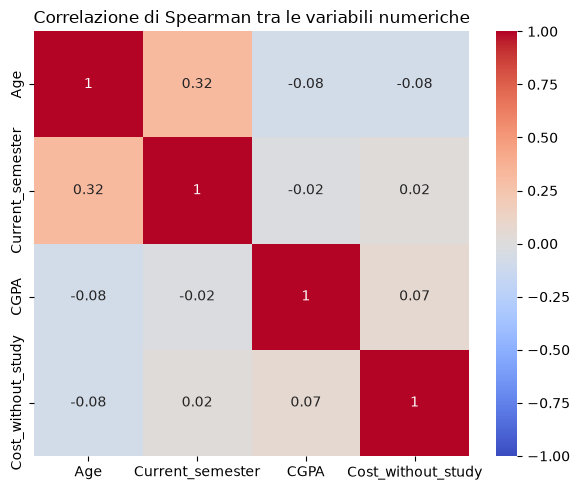

In [33]:
# correlazione di Spearman tra le variabili numeriche
numeric_corr = df[numeric_columns].corr(method="spearman").round(2)
print(numeric_corr)

fig, ax = plt.subplots(figsize=(6, 5))

sns.heatmap(
    numeric_corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=ax
)

ax.set_title("Correlazione di Spearman tra le variabili numeriche")

plt.tight_layout()
plt.show()

Le correlazioni tra le variabili numeriche sono deboli. L'unica che emerge è quella tra età e semestre (ρ = 0,32), prevedibile perché gli studenti più avanti negli studi sono in media più grandi. Tutte le altre coppie sono comprese tra −0,08 e 0,07: CGPA e costo non sono legati né all'età né al semestre, né tra loro. Le variabili numeriche portano quindi informazioni in gran parte indipendenti.

Finora ogni variabile è stata analizzata da sola. Qui le combiniamo in profili (stato di relazione, cerchia di amici, background familiare, stile di vita). Delle 36 combinazioni esistenti consideriamo le 27 con almeno 20 studenti, perché con meno studenti i tassi sono troppo instabili. Per ogni profilo riportiamo il tasso di depressione e il relativo intervallo di confidenza al 95% (metodo di Wilson): l'intervallo indica quanto il tasso è incerto, ed è tanto più ampio quanto più piccolo è il gruppo. Mostriamo i 10 profili con il tasso più alto e i 10 con il tasso più basso.

In [34]:
from statsmodels.stats.proportion import proportion_confint
# Variables selected for student profile analysis
profile_columns = [
    "Relationship_status",
    "friend_circle",
    "Family_background",
    "Living_style"
]

target = "Depression"

# Create student profiles from combinations of categorical variables
profile_summary = (
    df.groupby(profile_columns, observed=True)
    .agg(
        Total_Students=("Depression", "size"),
        Depression_Count=("Depression", lambda x: (x == "Yes").sum())
    )
    .reset_index()
)

#quanti profili esistono in tutto
print(f"Profili totali: {len(profile_summary)}")

# Calculate the percentage labeled as experiencing depression
profile_summary["Depression_Rate"] = (
    profile_summary["Depression_Count"]
    / profile_summary["Total_Students"]
    * 100
)

# Keep profiles with at least 20 students for more stable comparisons
profile_summary = profile_summary[
    profile_summary["Total_Students"] >= 20
].copy()

print(f"Profili con almeno 20 studenti: {len(profile_summary)}")

ci_low, ci_high = proportion_confint(
    profile_summary["Depression_Count"],
    profile_summary["Total_Students"],
    method="wilson"
)
profile_summary["CI_low"] = ci_low * 100
profile_summary["CI_high"] = ci_high * 100

profile_summary[["Depression_Rate", "CI_low", "CI_high"]] = (
    profile_summary[["Depression_Rate", "CI_low", "CI_high"]].round(2)
)

profile_summary = profile_summary.sort_values(
    "Depression_Rate",
    ascending=False
)

profile_summary.head(10)

Profili totali: 36
Profili con almeno 20 studenti: 27


,Relationship_status,friend_circle,Family_background,Living_style,Total_Students,Depression_Count,Depression_Rate,CI_low,CI_high
26,Single,No,Middle class,Bachelor,202,100,49.50,42.68,56.34
25,Single,No,Lower Middle class,Family,76,37,48.68,37.78,59.71
24,Single,No,Lower Middle class,Bachelor,95,42,44.21,34.64,54.23
27,Single,No,Middle class,Family,305,134,43.93,38.47,49.55
31,Single,Yes,Lower Middle class,Family,115,47,40.87,32.32,50.01
33,Single,Yes,Middle class,Family,442,160,36.20,31.86,40.78
29,Single,No,Rich class,Family,46,16,34.78,22.68,49.23
32,Single,Yes,Middle class,Bachelor,655,218,33.28,29.78,36.98
30,Single,Yes,Lower Middle class,Bachelor,623,195,31.30,27.78,35.05
3,Complicated,No,Middle class,Family,29,8,27.59,14.70,45.72


In [35]:
profile_summary.tail(10)

,Relationship_status,friend_circle,Family_background,Living_style,Total_Students,Depression_Count,Depression_Rate,CI_low,CI_high
17,In a Relationship,No,Rich class,Family,35,5,14.29,6.26,29.38
20,In a Relationship,Yes,Middle class,Bachelor,266,35,13.16,9.62,17.75
12,In a Relationship,No,Lower Middle class,Bachelor,54,7,12.96,6.42,24.42
22,In a Relationship,Yes,Rich class,Bachelor,78,10,12.82,7.12,22.02
13,In a Relationship,No,Lower Middle class,Family,40,5,12.50,5.46,26.11
18,In a Relationship,Yes,Lower Middle class,Bachelor,53,6,11.32,5.29,22.58
23,In a Relationship,Yes,Rich class,Family,203,17,8.37,5.29,13.00
9,Complicated,Yes,Middle class,Family,45,3,6.67,2.29,17.86
21,In a Relationship,Yes,Middle class,Family,430,24,5.58,3.78,8.17
8,Complicated,Yes,Middle class,Bachelor,21,0,0.00,0.00,15.46


Il profilo con il tasso più alto (single, senza amici, Middle class, Bachelor; 49,50%, IC 42,68–56,34) e quello più basso con un campione numeroso (in relazione, con amici, Middle class, Family; 5,58%, IC 3,78–8,17) hanno intervalli che non si sovrappongono: la differenza non è dovuta al caso. Nei profili più bassi compaiono solo persone in relazione o in situazione "Complicated", nei più alti quasi esclusivamente single: lo stato di relazione è il fattore che separa meglio i gruppi, seguito dalla cerchia di amici. Famiglia e stile di vita compaiono a entrambe le estremità e non sembrano discriminare.

I primi quattro profili per tasso (da 43,93% a 49,50%) hanno intervalli che si sovrappongono: tra loro non si distinguono, quindi l'ordine in classifica non è affidabile. Anche il valore vicino al 50% va letto come "tra il 43% e il 56%". I profili con meno di circa 50 studenti hanno intervalli molto ampi e vanno considerati indicativi (ad esempio 0 depressi su 21 studenti è compatibile con un tasso reale fino al 15%).

## Conclusioni

**Variabili categoriche.** Lo stato di relazione ha l'associazione più forte con la depressione (V di Cramér = 0,26, debole), seguito dalla cerchia di amici.  Il genere, da solo non associato (V = 0,007), è intrecciato con stato di relazione e stile di vita (V = 0,37 e 0,40).

**Variabili numeriche.** Solo il CGPA mostra una differenza chiara, con effetto piccolo (A = 0,56), concentrata nel quintile più basso (35,5% contro 24,8% degli altri). L'età è significativa ma trascurabile; semestre e costi non mostrano differenze affidabili. Le correlazioni tra le variabili numeriche sono deboli (solo età–semestre, ρ = 0,32).

**Profili.** Il profilo con il tasso più alto (single, senza amici, Middle class, Bachelor) ha il 49,5% di studenti depressi (IC 42,7–56,3%), contro il 26,9% dell'intero dataset. Gli intervalli dei profili più alti si sovrappongono, quindi l'ordine tra loro non è affidabile; è affidabile invece il divario con i profili più bassi (ad esempio 5,6%, IC 3,8–8,2%).
